<a href="https://colab.research.google.com/github/nhjung-phd/TimeSeriesAnalysis/blob/main/notebooks/Panel_Time_Series.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 6 — Panel Time Series: 12 Practical Labs
### 경영학·공학 박사과정 | Google Colab 통합 실습

**기존 `RealEstate.ipynb`의 핵심 맥락을 계승**: 지역/기업형 균형 패널, Pooled OLS, FE, RE, TWFE, Mundlak, 이질성 분석을 기반으로 12개 소절로 확장했습니다.

- **모든 데이터는 교육용 합성자료입니다.** 실제 주택가격이나 논문 실증 결과가 아닙니다.
- 모든 그래프의 제목·축·범례는 영어이며, Colab에서 한글 폰트 설치 없이 출력됩니다.
- 각 절은 **설명 → 수식 → 코드 → 표/그래프 → 해석 질문** 순서입니다.
- 일부 고급 방법은 직관과 진단을 위한 **교육용 구현**이며, 출판용 검증된 추정 패키지를 대체하지 않습니다.
- 실행: `Runtime > Run all` (시드=42, 인터넷/키 불필요).

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
rng=np.random.default_rng(SEED)
plt.rcParams.update({'font.family':'DejaVu Sans', 'axes.unicode_minus':False, 'figure.figsize':(9,4), 'axes.grid':True,'axes.spines.top':False,'axes.spines.right':False})
print('Synthetic panel exercises | seed:', SEED)

def fit(y, X, names=None, groups=None):
    X=np.asarray(X,dtype=float); y=np.asarray(y,dtype=float)
    model=sm.OLS(y,X)
    if groups is None: res=model.fit(cov_type='HC1')
    else: res=model.fit(cov_type='cluster',cov_kwds={'groups':np.asarray(groups)})
    nm=names if names is not None else [f'b{i}' for i in range(X.shape[1])]
    return res,pd.DataFrame({'coef':res.params,'se':res.bse,'p':res.pvalues},index=nm)

def plot_show(title, xlabel, ylabel):
    plt.title(title); plt.xlabel(xlabel); plt.ylabel(ylabel); plt.tight_layout(); plt.show()

Synthetic panel exercises | seed: 42


## 기본 1 — 패널 데이터의 이해
**질문:** 같은 지역을 여러 연도 관측하는 것과 매년 다른 지역을 관측하는 것은 무엇이 다른가?

$N$은 개체 수, $T$는 시점 수이며, 균형 패널은 모든 개체의 관측 시점이 동일합니다.

Synthetic region-level panel; not real estate market data
 N  T  observations  balanced
40 24           960      True
 unit  time    x     z      y  group
    0     0 1.43 -0.06  98.85      0
    0     1 1.23 -0.73  98.29      0
    0     2 0.02 -0.41 100.96      0
    0     3 0.92  0.63 100.76      0
    0     4 0.80  0.00 100.28      0
    0     5 0.90  0.34 101.58      0


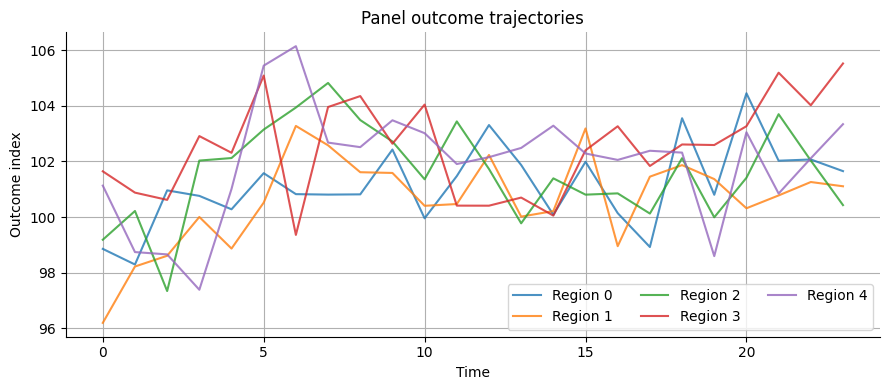

In [ ]:
N,T=40,24
prng=np.random.default_rng(SEED)
alpha=prng.normal(0,3,N); t=np.arange(T)
common=0.12*t+0.8*np.sin(t/4)
x=0.75*alpha[:,None]+prng.normal(0,1,(N,T))
z=prng.normal(0,1,(N,T))
grp=np.arange(N)%2
beta_i=np.where(grp==0,-1.5,-1.0)
y=100+alpha[:,None]+common[None,:]+beta_i[:,None]*x+0.8*z+prng.normal(0,0.8,(N,T))
df=pd.DataFrame({'unit':np.repeat(np.arange(N),T),'time':np.tile(t,N),'x':x.ravel(),'z':z.ravel(),'y':y.ravel(),'group':np.repeat(grp,T)})
print('Synthetic region-level panel; not real estate market data')
print(pd.DataFrame({'N':[N],'T':[T],'observations':[len(df)],'balanced':[df.groupby('unit').size().nunique()==1]}).to_string(index=False))
print(df.head(6).round(2).to_string(index=False))
for u in range(5):
 d=df[df.unit==u]; plt.plot(d.time,d.y,alpha=.8,label=f'Region {u}')
plt.legend(ncol=3);plot_show('Panel outcome trajectories','Time','Outcome index')

**결과 해석:** 한 지역을 반복 관측하므로 개체 고유의 차이와 시간 변화를 분리할 수 있습니다. 관측치 960개가 서로 독립적이라는 뜻은 아닙니다.

## 기본 2 — Between vs Within
**질문:** 지역 간 차이와 같은 지역의 시간 변화는 왜 다른가?

$x_{it}=\bar{x}_i+(x_{it}-\bar{x}_i)$ — 개체평균과 그 주변의 변동으로 분해합니다.

 Between SD  Within SD
      1.874      0.976


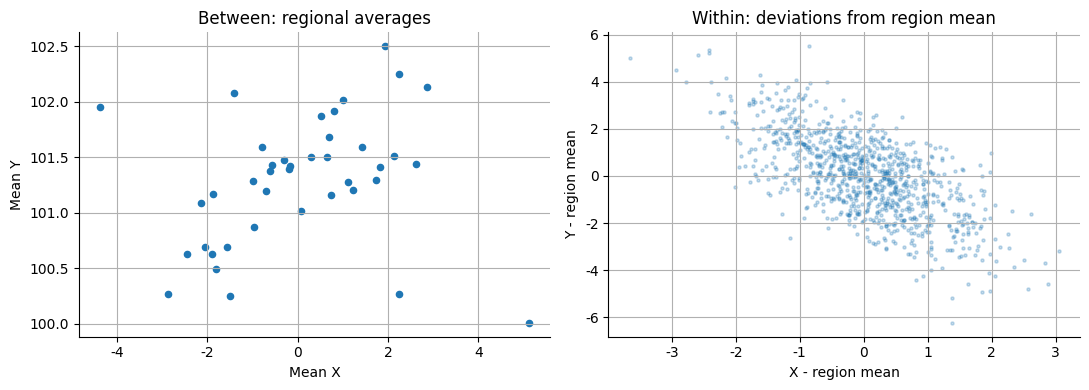

In [ ]:
agg=df.groupby('unit')[['x','y']].mean()
xd=df.x-df.groupby('unit').x.transform('mean'); yd=df.y-df.groupby('unit').y.transform('mean')
print(pd.DataFrame({'Between SD':[agg.x.std()],'Within SD':[xd.std()]}).round(3).to_string(index=False))
fig,ax=plt.subplots(1,2,figsize=(11,4))
ax[0].scatter(agg.x,agg.y,s=20);ax[0].set(title='Between: regional averages',xlabel='Mean X',ylabel='Mean Y')
ax[1].scatter(xd,yd,s=5,alpha=.25);ax[1].set(title='Within: deviations from region mean',xlabel='X - region mean',ylabel='Y - region mean')
plt.tight_layout();plt.show()

**해석:** Between은 지역이 원래 다른 정도, Within은 같은 지역이 시간에 따라 달라지는 정도를 비교합니다. 이 둘의 회귀 기울기는 같을 필요가 없습니다.

## 기본 3 — Pooled OLS와 누락변수
**질문:** 모든 지역을 하나로 합치면 고유한 지역 특성 때문에 기울기가 왜곡될까?

$y_{it}=\beta_0+\beta_1x_{it}+\beta_2z_{it}+\varepsilon_{it}$에서는 관측되지 않은 지역효과 $\alpha_i$가 오차항에 들어갑니다.

   Pooled coef  FE coef  True group-average slopes
X       -0.217   -1.244                      -1.25
Z        0.777    0.832                       0.80


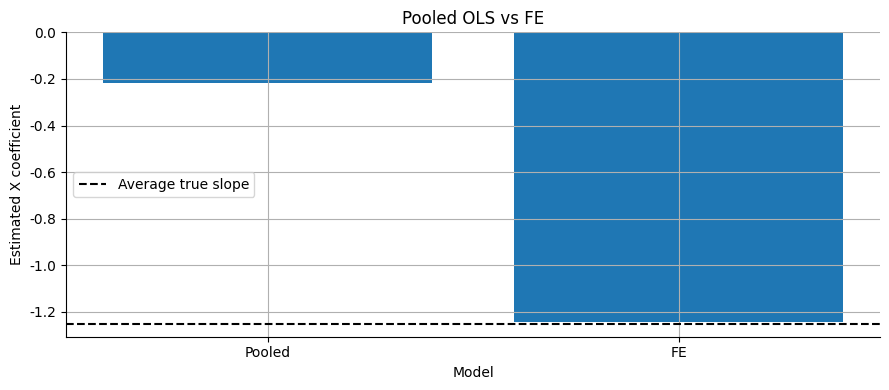

In [ ]:
X=np.column_stack([np.ones(len(df)),df.x,df.z])
pooled,pt=fit(df.y,X,['Intercept','X','Z'],df.unit)
W=df[['y','x','z']]-df.groupby('unit')[['y','x','z']].transform('mean')
fe,ft=fit(W.y,W[['x','z']],['X','Z'],df.unit)
print(pd.DataFrame({'Pooled coef':pt.coef[['X','Z']],'FE coef':ft.coef[['X','Z']],'True group-average slopes':[-1.25,.8]},index=['X','Z']).round(3))
plt.bar(['Pooled','FE'],[pt.loc['X','coef'],ft.loc['X','coef']]);plt.axhline(-1.25,ls='--',color='black',label='Average true slope');plt.legend();plot_show('Pooled OLS vs FE','Model','Estimated X coefficient')

**해석:** Pooled OLS는 지역별 고유한 환경이 X와 관련될 때 편향될 수 있습니다. FE는 시간에 따라 불변인 지역 고유특성을 제거하지만, 시변 교란까지 자동 제거하지는 않습니다.

## 기본 4 — 고정효과(FE): 평균 제거와 손계산
**질문:** 지역마다 다른 기준선 $\alpha_i$는 평균을 빼면 왜 사라지는가?

$y_{it}-\bar y_i=\beta(x_{it}-\bar x_i)+(\varepsilon_{it}-\bar\varepsilon_i)$

Illustrative first 5 periods of Region 0:
 unit  time      y    x  y_dm  x_dm
    0     0  98.85 1.43 -0.97  0.55
    0     1  98.29 1.23 -1.54  0.35
    0     2 100.96 0.02  1.13 -0.86
    0     3 100.76 0.92  0.93  0.04
    0     4 100.28 0.80  0.45 -0.08
Whole panel within estimate:
     coef      se    p
X -1.2440  0.0601  0.0
Z  0.8318  0.0360  0.0


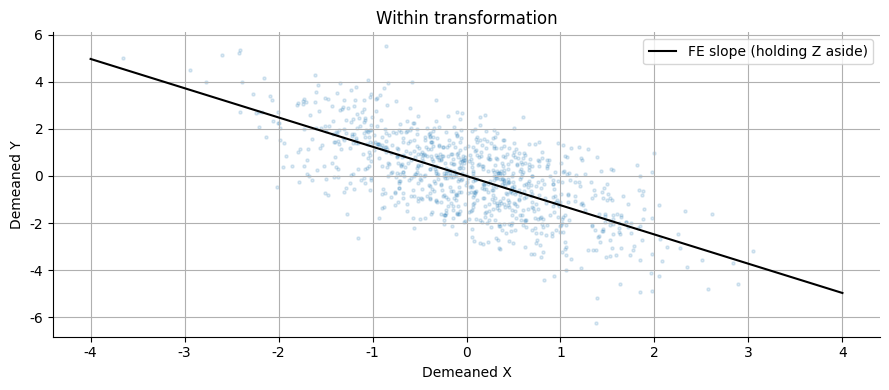

In [ ]:
small=df[df.unit.isin([0,1])].head(5).copy()
small['y_dm']=small.y-small.groupby('unit').y.transform('mean')
small['x_dm']=small.x-small.groupby('unit').x.transform('mean')
print('Illustrative first 5 periods of Region 0:')
print(small[['unit','time','y','x','y_dm','x_dm']].round(2).to_string(index=False))
print('Whole panel within estimate:'); print(ft.round(4))
plt.scatter(W.x,W.y,s=5,alpha=.15);plt.plot([-4,4],np.array([-4,4])*ft.loc['X','coef'],color='black',label='FE slope (holding Z aside)');plt.legend();plot_show('Within transformation','Demeaned X','Demeaned Y')

**해석:** 같은 지역의 평균을 빼면 해당 지역의 불변 수준이 없어집니다. 다변량 FE에서 산점도 선은 Z를 통제한 조건부 계수이므로 단순 산점도와 정확히 일치하지 않을 수 있습니다.

## 기본 5 — RE와 Mundlak 진단
**질문:** 개체효과가 설명변수와 무관하다는 RE 가정은 믿을 만한가?

$y_{it}=\beta x_{it}+\alpha_i+\lambda_t+\varepsilon_{it}$, 전통적 RE는 $\mathrm{Cov}(\alpha_i,x_{it})=0$을 요구합니다.

Mundlak 보조회귀는 지역별 $\bar x_i,\bar z_i$를 추가하여 그 계수가 0인지 검토합니다.

FE/RE coefficient table:
      FE     RE
X -1.244 -0.816
Z  0.832  0.807
Mundlak diagnostics:
          coef      se      p
Mean X  1.3125  0.0778  0.000
Mean Z  0.1214  0.4010  0.762
Joint Wald p-value: 0.0


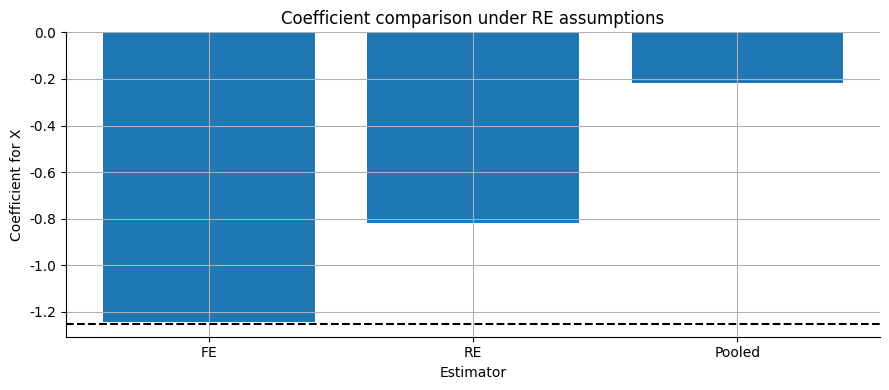

In [ ]:
Tn=T
# RE feasible GLS via variance components
r_within=np.asarray(fe.resid); sig_e2=float(np.sum(r_within**2)/(len(df)-N-2))
between=df.groupby('unit')[['y','x','z']].mean()
br=sm.OLS(between.y,sm.add_constant(between[['x','z']])).fit()
sig_b2=float(np.sum(br.resid**2)/(N-3)); sig_a2=max(1e-6,sig_b2-sig_e2/Tn)
theta=1-np.sqrt(sig_e2/(sig_e2+Tn*sig_a2))
means=df.groupby('unit')[['y','x','z']].transform('mean')
Q=df[['y','x','z']]-theta*means
re,rt=fit(Q.y,np.column_stack([np.ones(len(df))*(1-theta),Q.x,Q.z]),['Intercept','X','Z'],df.unit)
m=df.groupby('unit')[['x','z']].transform('mean'); M=np.column_stack([np.ones(len(df)),df.x,df.z,m.x,m.z])
mun,mt=fit(df.y,M,['Intercept','X','Z','Mean X','Mean Z'],df.unit)
wald=mun.wald_test(np.array([[0,0,0,1,0],[0,0,0,0,1]]),scalar=True)
print('FE/RE coefficient table:')
print(pd.DataFrame({'FE':ft.coef[['X','Z']],'RE':rt.coef[['X','Z']]}).round(3))
print('Mundlak diagnostics:');print(mt.loc[['Mean X','Mean Z']].round(4)); print('Joint Wald p-value:',round(float(wald.pvalue),6))
plt.bar(['FE','RE','Pooled'],[ft.loc['X','coef'],rt.loc['X','coef'],pt.loc['X','coef']]);plt.axhline(-1.25,ls='--',color='black');plot_show('Coefficient comparison under RE assumptions','Estimator','Coefficient for X')

**해석:** Mundlak의 평균항이 유의하면 RE의 단순 외생성 가정이 의심됩니다. 이 검정은 기계적인 모형 선택 규칙이 아니며, 여기의 RE 구현은 균형 패널 교육용 분산성분 추정입니다.

## 기본 6 — TWFE: 지역효과와 시점효과
**질문:** 경기·정책처럼 모든 지역에 영향을 주는 공통 시점 충격도 제거할 수 있을까?

$y_{it}=\beta_1x_{it}+\beta_2z_{it}+\alpha_i+\lambda_t+\varepsilon_{it}$

균형 패널에서는 이중 평균 제거 $\ddot y_{it}=y_{it}-\bar y_i-\bar y_t+\bar y$를 사용할 수 있습니다.

      FE   TWFE
X -1.244 -1.252
Z  0.832  0.839


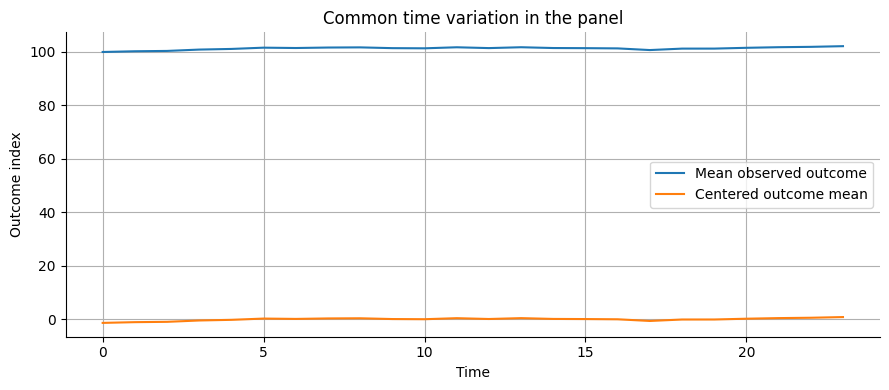

In [ ]:
def double_demean(frame,cols):
 return frame[cols]-frame.groupby('unit')[cols].transform('mean')-frame.groupby('time')[cols].transform('mean')+frame[cols].mean()
D=double_demean(df,['y','x','z'])
tw,tt=fit(D.y,D[['x','z']],['X','Z'],df.unit)
print(pd.DataFrame({'FE':ft.coef[['X','Z']],'TWFE':tt.coef[['X','Z']]}).round(3))
raw_time=df.groupby('time').y.mean(); residual_time=pd.Series(tw.resid).groupby(df.time).mean()
plt.plot(raw_time.index,raw_time.values,label='Mean observed outcome');plt.plot(raw_time.index,raw_time.values-raw_time.mean(),label='Centered outcome mean');plt.legend();plot_show('Common time variation in the panel','Time','Outcome index')

**해석:** TWFE는 지역별 불변 요인과 모든 지역의 공통 시점 충격을 통제합니다. 시점마다 모든 지역에 동일한 설명변수는 시간효과에 흡수되어 별도 계수를 식별할 수 없습니다.

## 기본 7 — 모형 선택과 기본 실습
**질문:** 회귀표에서 실제로 무엇을 비교하고 보고해야 할까?

계수·군집 표준오차·추정대상·식별가정을 함께 비교합니다.

Regression comparison:
   Pooled     FE     RE   TWFE
X  -0.217 -1.244 -0.816 -1.252
Z   0.777  0.832  0.807  0.839
Clustered SE:
   Pooled     FE     RE   TWFE
X   0.056  0.060  0.069  0.055
Z   0.050  0.036  0.040  0.028


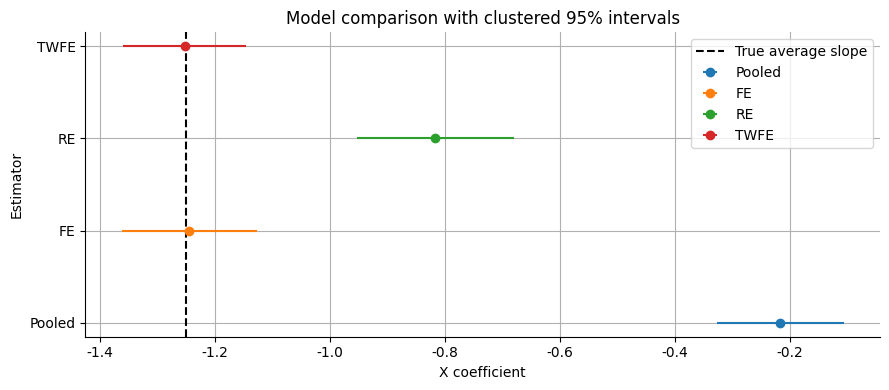

In [ ]:
coef_compare=pd.DataFrame({'Pooled':pt.coef[['X','Z']],'FE':ft.coef[['X','Z']],'RE':rt.coef[['X','Z']],'TWFE':tt.coef[['X','Z']]})
se_compare=pd.DataFrame({'Pooled':pt.se[['X','Z']],'FE':ft.se[['X','Z']],'RE':rt.se[['X','Z']],'TWFE':tt.se[['X','Z']]})
print('Regression comparison:');print(coef_compare.round(3));print('Clustered SE:');print(se_compare.round(3))
for name in coef_compare.columns:
 plt.errorbar(coef_compare.loc['X',name],list(coef_compare.columns).index(name),xerr=1.96*se_compare.loc['X',name],fmt='o',label=name)
plt.axvline(-1.25,color='black',ls='--',label='True average slope');plt.yticks(np.arange(4),coef_compare.columns);plt.legend(loc='best');plot_show('Model comparison with clustered 95% intervals','X coefficient','Estimator')

**해석:** 동일한 자료라도 모형의 통제 범위가 다르면 계수와 불확실성이 달라집니다. 95% 구간은 여기서는 군집 강건 정규근사로 표시한 교육용 그림입니다.

## 심화 1 — FE의 식별가정과 한계
**질문:** FE를 사용했는데도 시간에 따라 바뀌는 숨은 요인이 있으면?

$\mathrm{Cov}(x_{it},u_{it}\mid\alpha_i,\lambda_t)\neq0$이면 FE가 인과효과를 보장하지 않습니다.

         TWFE original  TWFE with time-varying confounding
X slope         -1.252                               0.016


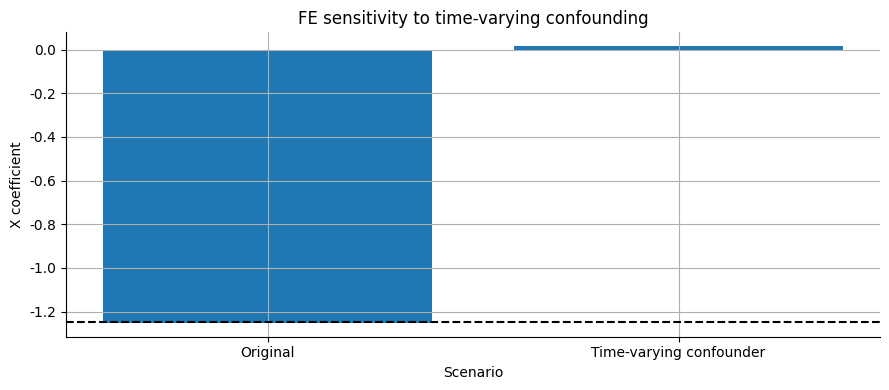

In [ ]:
conf=df.copy(); rng2=np.random.default_rng(202)
sh=rng2.normal(0,1,len(conf)); conf['hidden_t']=sh
conf['x_bad']=conf.x+0.8*sh
conf['y_bad']=conf.y+1.5*sh
Zbad=double_demean(conf,['y_bad','x_bad','z'])
bad,bt=fit(Zbad.y_bad,Zbad[['x_bad','z']],['X (confounded)','Z'],conf.unit)
print(pd.DataFrame({'TWFE original':[tt.loc['X','coef']],'TWFE with time-varying confounding':[bt.loc['X (confounded)','coef']]},index=['X slope']).round(3))
plt.bar(['Original','Time-varying confounder'],[tt.loc['X','coef'],bt.loc['X (confounded)','coef']]);plt.axhline(-1.25,color='black',ls='--');plot_show('FE sensitivity to time-varying confounding','Scenario','X coefficient')

**해석:** FE는 불변 교란에 강하지만 시변 교란·역인과·측정오차·간섭이 남으면 인과해석은 여전히 제한됩니다. 여기서는 교란변수를 의도적으로 삽입했습니다.

## 심화 2 — 동적 패널과 Nickell 편향
**질문:** 어제의 결과가 오늘 결과를 설명하면 짧은 패널의 FE는 어떻게 되는가?

$y_{it}=\rho y_{i,t-1}+\alpha_i+\varepsilon_{it}$에서 짧은 $T$의 FE는 일반적으로 편향됩니다.

다음 실습은 **Nickell 편향의 시뮬레이션**이며 Difference/System GMM을 구현한 것은 아닙니다.

 T  FE rho
 6   0.352
10   0.456
20   0.604
50   0.653


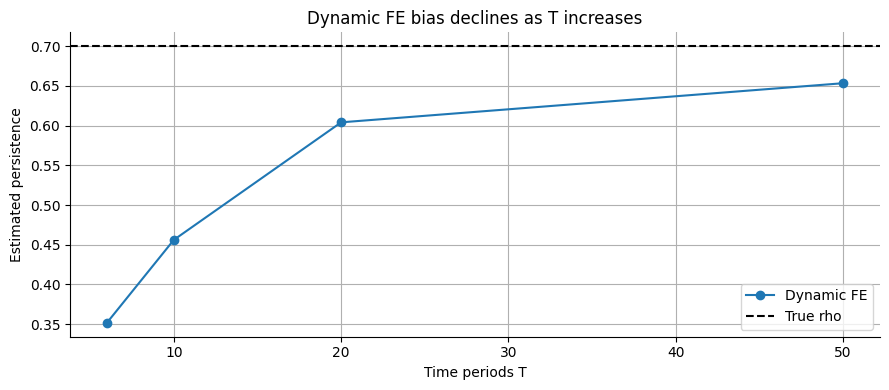

In [ ]:
def dynamic_fe_est(Tdynamic, seed=42,N=200,rho=.7):
 r=np.random.default_rng(seed); a=r.normal(0,1,N); e=r.normal(0,1,(N,Tdynamic+80)); Y=np.zeros((N,Tdynamic+80))
 for j in range(1,Y.shape[1]): Y[:,j]=rho*Y[:,j-1]+a+e[:,j]
 curr=Y[:,-Tdynamic:].copy(); lag=Y[:,-Tdynamic-1:-1].copy()
 yc=curr-curr.mean(axis=1,keepdims=True);xl=lag-lag.mean(axis=1,keepdims=True)
 return float((yc*xl).sum()/(xl*xl).sum())
Ts=[6,10,20,50];dyn=pd.DataFrame({'T':Ts,'FE rho':[dynamic_fe_est(k,seed=40+j) for j,k in enumerate(Ts)]})
print(dyn.round(3).to_string(index=False))
plt.plot(dyn['T'],dyn['FE rho'],marker='o',label='Dynamic FE');plt.axhline(.7,color='black',ls='--',label='True rho');plt.legend();plot_show('Dynamic FE bias declines as T increases','Time periods T','Estimated persistence')

**해석:** 시점 수가 짧으면 지연 종속변수와 변환된 오차가 상관되어 FE 편향이 나타날 수 있습니다. GMM 사용 시에도 도구변수 유효성·과다도구·AR(2)·Hansen 검증이 별도로 필요합니다.

## 심화 3 — 시차 도입 TWFE와 이질적 효과
**질문:** 정책 시작 시점이 지역마다 다르면 단일 TWFE 계수가 어떤 비교를 섞는가?

다음은 **코호트별 효과가 서로 다른 가상 패널**에서 단순 TWFE와 코호트별 명시적 진실 효과를 비교합니다. Goodman–Bacon 분해나 Sun–Abraham/Callaway–Sant'Anna 추정기의 구현은 아닙니다.

TWFE pooled coefficient: 3.4
cohort  true_effect  start
 Early          2.0      8
  Late          5.0     12


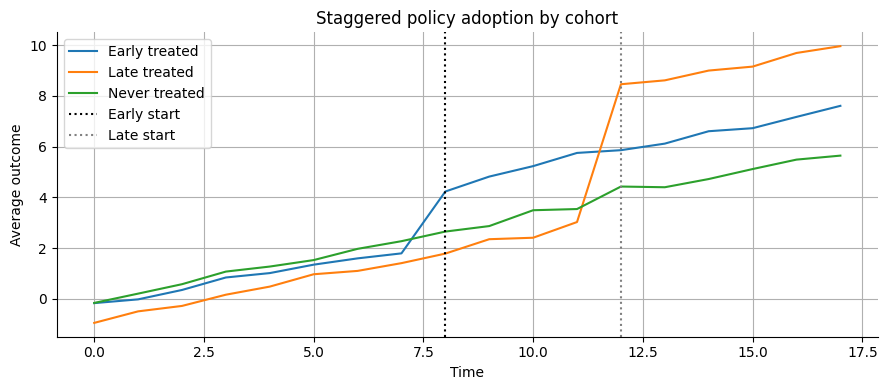

In [ ]:
r=np.random.default_rng(20); N3,T3=60,18; g=np.repeat([8,12,999],20)
alpha3=r.normal(0,2,N3); trend=.35*np.arange(T3); err=r.normal(0,.5,(N3,T3))
base=alpha3[:,None]+trend[None,:]+err
post=(np.arange(T3)[None,:]>=g[:,None]); tau3=np.where(g==8,2.0,np.where(g==12,5.,0.))
ys=base+post*tau3[:,None]
sdf=pd.DataFrame({'unit':np.repeat(np.arange(N3),T3),'time':np.tile(np.arange(T3),N3),'cohort':np.repeat(g,T3),'treated':post.ravel().astype(int),'outcome':ys.ravel()})
Xd=double_demean(sdf.rename(columns={'outcome':'y','treated':'x'}),['y','x'])
stw,st=fit(Xd.y,Xd[['x']],['TWFE treatment'],sdf.unit)
cohort_true=pd.DataFrame({'cohort':['Early','Late'],'true_effect':[2.,5.],'start':[8,12]})
print('TWFE pooled coefficient:',round(float(st.iloc[0].coef),3)); print(cohort_true.to_string(index=False))
for cohort in [8,12,999]:
 sub=sdf[sdf.cohort==cohort]; plt.plot(sub.groupby('time').outcome.mean(),label={8:'Early treated',12:'Late treated',999:'Never treated'}[cohort])
plt.axvline(8,color='black',ls=':',label='Early start');plt.axvline(12,color='grey',ls=':',label='Late start');plt.legend();plot_show('Staggered policy adoption by cohort','Time','Average outcome')

**해석:** 서로 다른 코호트의 처치효과를 하나의 TWFE로 합치면 효과 이질성 때문에 해석이 어렵습니다. 실제 논문에서는 코호트–시점 ATT 또는 적합한 최신 DID 추정량을 사용해야 합니다.

## 심화 4 — 패널 추론·표준오차·강건성
**질문:** 같은 지역을 여러 기간 관측한 오차를 모두 독립이라고 해도 될까?

군집 표준오차와 단순 HC1을 비교하고, 비교 대상 또는 시점 구간이 바뀔 때 계수가 얼마나 바뀌는지 확인합니다.

   HC1 SE  Cluster-by-unit SE
X  0.0243              0.0564
        specification    coef     se
            All units -1.2521 0.0547
Exclude first 5 units -1.2350 0.0587
     First 18 periods -1.2725 0.0610


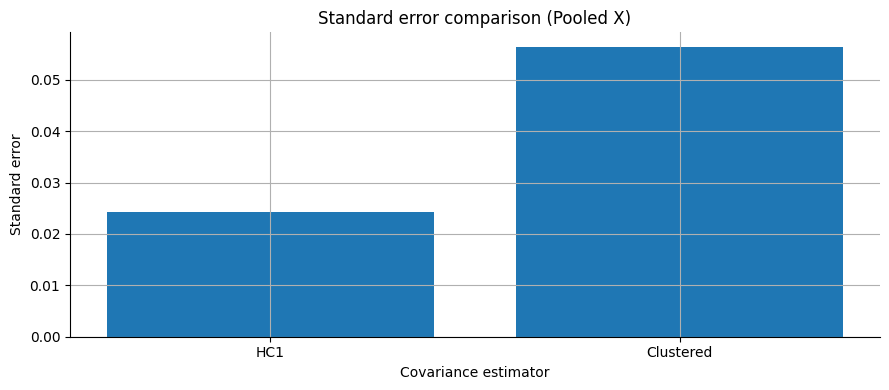

In [ ]:
ols_hc,oh=fit(df.y,X,['Intercept','X','Z'])
comparison=pd.DataFrame({'HC1 SE':[oh.loc['X','se']],'Cluster-by-unit SE':[pt.loc['X','se']]},index=['X'])
print(comparison.round(4).to_string())
robust=[]
for label,frame in [('All units',df),('Exclude first 5 units',df[df.unit>=5]),('First 18 periods',df[df.time<18])]:
 q=double_demean(frame,['y','x','z']);rr,rrt=fit(q.y,q[['x','z']],['X','Z'],frame.unit);robust.append((label,rrt.loc['X','coef'],rrt.loc['X','se']))
robdf=pd.DataFrame(robust,columns=['specification','coef','se']);print(robdf.round(4).to_string(index=False))
plt.bar(['HC1','Clustered'],[oh.loc['X','se'],pt.loc['X','se']]);plot_show('Standard error comparison (Pooled X)','Covariance estimator','Standard error')

**해석:** 군집표준오차는 개체 내 임의의 상관을 허용합니다. 군집 수가 적으면 추가적인 소표본 방법이 필요하며, 양방향 군집이나 Driscoll–Kraay는 자료 구조에 맞춰 별도로 검토해야 합니다.

## 심화 5 — 논문형 연구설계와 재현성
**질문:** 지역별 가격지수 연구를 실제로 제출한다면 어떤 표·그래프·식별 설명이 필요한가?

실습용 결과를 연구설계 보고서로 정리합니다. 아래는 **합성자료의 예시 보고**이며 실증적 주장으로 사용해서는 안 됩니다.

       section                                                             report_item
            RQ        Is variation in X associated with within-region outcome changes?
          Unit                                Synthetic regions (N=40), periods (T=24)
      Estimand     Within-region conditional association, not identified causal effect
      Baseline                                                              Pooled OLS
       Primary                                             TWFE + cluster-by-region SE
Identification Requires conditional exogeneity; synthetic confounder sensitivity shown
   Diagnostics    Mundlak auxiliary test; time-varying confounder; alternative samples
    Limitation                 Synthetic data; no verified real-world causal inference
Publishable-style table (synthetic only):
     model  X coefficient  SE (cluster)
Pooled OLS        -0.2168        0.0564
        FE        -1.2440        0.0601
        RE        -0.8162        0.0694
      TWFE     

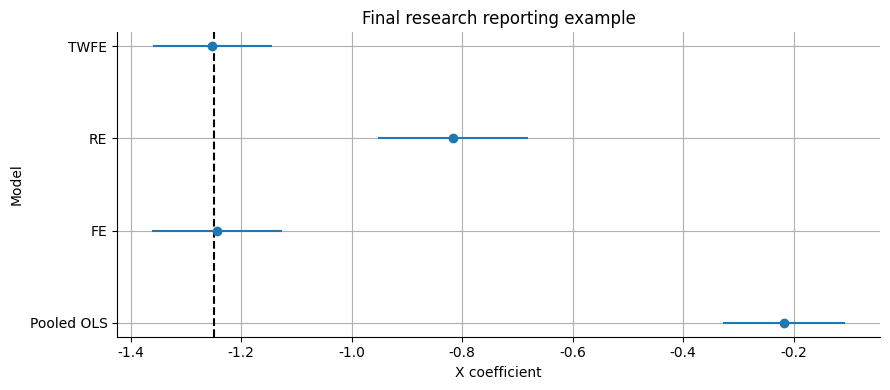

In [ ]:
research=pd.DataFrame([
 ['RQ','Is variation in X associated with within-region outcome changes?'],
 ['Unit','Synthetic regions (N=40), periods (T=24)'],
 ['Estimand','Within-region conditional association, not identified causal effect'],
 ['Baseline','Pooled OLS'],['Primary','TWFE + cluster-by-region SE'],
 ['Identification','Requires conditional exogeneity; synthetic confounder sensitivity shown'],
 ['Diagnostics','Mundlak auxiliary test; time-varying confounder; alternative samples'],
 ['Limitation','Synthetic data; no verified real-world causal inference']
],columns=['section','report_item'])
print(research.to_string(index=False))
report=pd.DataFrame({'model':['Pooled OLS','FE','RE','TWFE'],'X coefficient':[pt.loc['X','coef'],ft.loc['X','coef'],rt.loc['X','coef'],tt.loc['X','coef']], 'SE (cluster)':[pt.loc['X','se'],ft.loc['X','se'],rt.loc['X','se'],tt.loc['X','se']]})
print('Publishable-style table (synthetic only):');print(report.round(4).to_string(index=False))
plt.errorbar(report['X coefficient'],report['model'],xerr=1.96*report['SE (cluster)'],fmt='o');plt.axvline(-1.25,color='black',ls='--');plot_show('Final research reporting example','X coefficient','Model')

### 최종 토론과 보고 점검
1. 같은 데이터에서 Pooled·FE·RE·TWFE 계수가 달라지는 이유는 무엇인가?
2. 변하지 않는 개체효과를 제거했다고 인과효과가 되는가?
3. 사전추세·시변교란·도입시점·간섭·군집오차를 어떻게 진단하는가?
4. 패널 수가 적거나 시점이 짧을 때 어떤 추론·편향 문제가 있는가?

**주의:** 그래프는 모두 영어로 출력하지만 노트북의 설명은 한국어입니다. 실제 논문용으로 전환할 때에는 공개 데이터의 원천·시점별 가용성·변수 정의·결측·패널 균형 여부부터 재검증해야 합니다.